# Clasificación landuse con CNN

Continuación del reto 1: se conservan la **CNN base** y la **CNN mejorada**
porque son las dos referencias desde cero que el reto 1 dejó identificadas. La
CNN mejorada adopta ahora la receta **v2** que ganó en el reto 1 (augmentación
suave, `lr=3e-4`, `label_smoothing` y early stopping sobre `val_loss`) y las dos
redes incorporan `Rescaling(1/255)` **dentro del modelo**, igual que en la
entrega anterior.

| Variante | Carpeta | Descripción |
|---|---|---|
| CNN base | `resultados/cnn/base/` | Arquitectura del ejemplo: 8 → 16 → 32 filtros, `Flatten` + `Dense(3)`. |
| CNN mejorada | `resultados/cnn/mejorada/` | Receta v2: 32-64-128, dos convoluciones por bloque, BN, GAP, `Dense(128)`, `Dropout(0.4)` y `class_weight`. |

Las imágenes se cargan **sin normalizar** y se redimensionan a 128×128; la capa
`Rescaling(1/255)` vive dentro de cada modelo. El split es el común del reto:
75 % train, 15 % validación y 25 % test, estratificado con semilla 20. El test
**no** se usa para early stopping.

Los modelos ya entrenados se cargan por defecto. Para volver a entrenarlos,
cambia `FORCE_RETRAIN = True` en la celda de configuración.


## Configuración

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.layers import (
    Activation,
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    GlobalAveragePooling2D,
    Input,
    MaxPooling2D,
)
from keras.models import Sequential
from keras.optimizers import Adam

import common_landuse as cl

FORCE_RETRAIN = False
sns.set_theme(style="whitegrid", context="notebook")
keras.utils.set_random_seed(cl.SEED)
np.random.seed(cl.SEED)

I0000 00:00:1795149610.610952   23424 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795149613.934481   23424 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Carga del dataset y split común

In [2]:
data = cl.load_split_data()
X_train = data["X_train"].astype("float32")
X_val = data["X_val"].astype("float32")
X_test = data["X_test"].astype("float32")
y_train_labels = data["y_train"]
y_val_labels = data["y_val"]
y_test_labels = data["y_test"]
test_paths = data["test_paths"]

y_train = cl.one_hot(y_train_labels)
y_val = cl.one_hot(y_val_labels)

# Class weights, kept for continuity with the reto 1 recipe. The landuse
# training split is balanced, so the weights are close to 1.0.
class_counts = {name: int(np.sum(y_train_labels == name)) for name in cl.CLASSES}
total_train = sum(class_counts.values())
class_weight = {
    index: total_train / (len(cl.CLASSES) * class_counts[name])
    for index, name in enumerate(cl.CLASSES)
}

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Test distribution:", {name: int(np.sum(y_test_labels == name)) for name in cl.CLASSES})
print("Train distribution:", class_counts)
print(
    "class_weight:",
    {name: round(class_weight[index], 3) for index, name in enumerate(cl.CLASSES)},
)


Train: (956, 128, 128, 3) | Validation: (169, 128, 128, 3) | Test: (375, 128, 128, 3)
Test distribution: {'denseresidential': 125, 'harbor': 125, 'river': 125}
Train distribution: {'denseresidential': 319, 'harbor': 319, 'river': 318}
class_weight: {'denseresidential': 0.999, 'harbor': 0.999, 'river': 1.002}


## Arquitecturas

In [3]:
def build_base_cnn():
    model = Sequential(
        [
            Input(shape=(128, 128, 3)),
            layers.Rescaling(1.0 / 255),
            Conv2D(8, (3, 3), padding="same"),
            Activation("relu"),
            MaxPooling2D((2, 2)),
            Conv2D(16, (3, 3), padding="same"),
            Activation("relu"),
            MaxPooling2D((2, 2)),
            Conv2D(32, (3, 3), padding="same"),
            Activation("relu"),
            MaxPooling2D((2, 2)),
            Flatten(),
            Dense(len(cl.CLASSES)),
            Activation("softmax"),
        ],
        name="cnn_base_landuse",
    )
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model


def conv_block(x, filters):
    x = Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return MaxPooling2D((2, 2))(x)


def build_improved_cnn_v2():
    inputs = Input(shape=(128, 128, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.05)(x)
    x = layers.Rescaling(1.0 / 255)(x)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(0.4)(x)
    outputs = Dense(len(cl.CLASSES), activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="cnn_improved_v2_landuse")
    model.compile(
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
        optimizer=Adam(learning_rate=3e-4),
        metrics=["accuracy"],
    )
    return model


## Entrenamiento o carga desde caché

In [4]:
def fit_base(model):
    history, seconds = cl.train_keras_model(
        model, X_train, y_train, X_val, y_val, epochs=15, batch_size=32
    )
    return model, history, seconds


def evaluate_base(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cl.predict_keras(model, X_test)
    predicted = np.array(cl.CLASSES)[predicted_idx]
    metrics = cl.compute_metrics(
        name="CNN base",
        family="CNN",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history.history["loss"]),
        hyperparameters={
            "filters": [8, 16, 32],
            "optimizer": "Adam",
            "lr": 1e-3,
            "batch_size": 32,
            "epochs": 15,
            "augmentation": False,
            "rescaling": "1/255 inside the model",
        },
        notes=(
            "Sequential architecture from the professor's base notebook, aligned with "
            "reto 1: Rescaling(1/255) lives inside the model."
        ),
    )
    cl.save_results(
        "cnn/base",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics


def fit_improved_v2(model):
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-6, verbose=1),
    ]
    history, seconds = cl.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=100,
        batch_size=32,
        callbacks=callbacks,
        class_weight=class_weight,
    )
    return model, history, seconds


def evaluate_improved_v2(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cl.predict_keras(model, X_test)
    predicted = np.array(cl.CLASSES)[predicted_idx]
    metrics = cl.compute_metrics(
        name="CNN mejorada",
        family="CNN",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history.history["loss"]),
        hyperparameters={
            "filters": [32, 64, 128],
            "convs_per_block": 2,
            "optimizer": "Adam",
            "lr": 3e-4,
            "loss": "categorical_crossentropy",
            "label_smoothing": 0.05,
            "batch_size": 32,
            "epochs_max": 100,
            "early_stopping": "val_loss, patience=20",
            "augmentation": "flip + rotation 0.05",
            "class_weight": True,
            "iteration": 2,
            "rescaling": "1/255 inside the model",
        },
        notes=(
            "Improved CNN with the reto 1 v2 recipe: softer augmentation, lr 3e-4, "
            "label smoothing and early stopping on val_loss."
        ),
    )
    cl.save_results(
        "cnn/mejorada",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics


In [5]:
model_base, history_base, metrics_base, retrained_base = cl.load_or_train(
    "cnn/base",
    build_model=build_base_cnn,
    fit_model=fit_base,
    evaluate_model=evaluate_base,
    force=FORCE_RETRAIN,
)
print("Test accuracy:", round(metrics_base["accuracy"], 4))

[train] Training model in /home/andres/Desktop/vision-por-computador/guia-4/reto-2/resultados/cnn/base


E0000 00:00:1795149625.695834   23424 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:68



Epoch 1/15


30/30 - 10s - 347ms/step - accuracy: 0.4916 - loss: 0.9966 - val_accuracy: 0.5503 - val_loss: 0.9122


Epoch 2/15


30/30 - 7s - 247ms/step - accuracy: 0.6862 - loss: 0.7553 - val_accuracy: 0.6864 - val_loss: 0.7447


... (23 outputs left out)

30/30 - 7s - 218ms/step - accuracy: 0.9948 - loss: 0.0418 - val_accuracy: 0.9112 - val_loss: 0.2664


Epoch 15/15


30/30 - 6s - 215ms/step - accuracy: 0.9948 - loss: 0.0447 - val_accuracy: 0.9053 - val_loss: 0.2510


Results saved to: /home/andres/Desktop/vision-por-computador/guia-4/reto-2/resultados/cnn/base
Test accuracy: 0.8933


In [6]:
model_improved, history_improved, metrics_improved, retrained_improved = cl.load_or_train(
    "cnn/mejorada",
    build_model=build_improved_cnn_v2,
    fit_model=fit_improved_v2,
    evaluate_model=evaluate_improved_v2,
    force=FORCE_RETRAIN,
)
print("Test accuracy:", round(metrics_improved["accuracy"], 4))


[train] Training model in /home/andres/Desktop/vision-por-computador/guia-4/reto-2/resultados/cnn/mejorada


Epoch 1/100


30/30 - 104s - 3s/step - accuracy: 0.7186 - loss: 0.7232 - val_accuracy: 0.3373 - val_loss: 1.1568 - learning_rate: 3.0000e-04


Epoch 2/100


30/30 - 93s - 3s/step - accuracy: 0.8996 - loss: 0.4348 - val_accuracy: 0.3373 - val_loss: 1.6401 - learning_rate: 3.0000e-04


Epoch 3/100


... (203 outputs left out)

30/30 - 84s - 3s/step - accuracy: 1.0000 - loss: 0.1885 - val_accuracy: 0.9763 - val_loss: 0.2117 - learning_rate: 1.0000e-06


Epoch 100: early stopping


Restoring model weights from the end of the best epoch: 80.


Results saved to: /home/andres/Desktop/vision-por-computador/guia-4/reto-2/resultados/cnn/mejorada
Test accuracy: 0.992


## Comparación de las dos variantes

In [7]:
comparison = pd.DataFrame(
    [
        {
            "model": metrics_base["name"],
            "accuracy": metrics_base["accuracy"],
            "f1_macro": metrics_base["f1_macro"],
            "parameters": metrics_base["parameters"],
            "training_seconds": metrics_base["training_seconds"],
        },
        {
            "model": metrics_improved["name"],
            "accuracy": metrics_improved["accuracy"],
            "f1_macro": metrics_improved["f1_macro"],
            "parameters": metrics_improved["parameters"],
            "training_seconds": metrics_improved["training_seconds"],
        },
    ]
)
display = comparison.rename(
    columns={
        "model": "Modelo",
        "accuracy": "Accuracy",
        "f1_macro": "F1 macro",
        "parameters": "Parámetros",
        "training_seconds": "Entrenamiento (s)",
    }
)
display.round(4)

,Modelo,Accuracy,F1 macro,Parámetros,Entrenamiento (s)
0,CNN base,0.8933,0.8924,30611,110.64
1,CNN mejorada,0.9920,0.9920,305251,8338.90


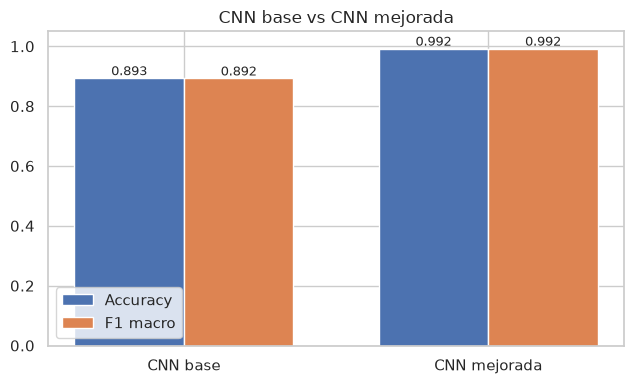

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
positions = np.arange(len(comparison))
width = 0.36
ax.bar(positions - width / 2, comparison["accuracy"], width, label="Accuracy")
ax.bar(positions + width / 2, comparison["f1_macro"], width, label="F1 macro")
ax.set_xticks(positions, comparison["model"])
ax.set_ylim(0, 1.05)
ax.set_title("CNN base vs CNN mejorada")
ax.legend()
for index, (accuracy, f1_value) in enumerate(
    zip(comparison["accuracy"], comparison["f1_macro"])
):
    ax.text(index - width / 2, accuracy + 0.01, f"{accuracy:.3f}", ha="center", fontsize=9)
    ax.text(index + width / 2, f1_value + 0.01, f"{f1_value:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## Observaciones

* La CNN base mantiene la arquitectura del ejemplo y ahora usa
  `Rescaling(1/255)` dentro del modelo, igual que el reto 1. Aprende rápido,
  pero sobreajusta: la accuracy de entrenamiento sube mucho más que la de
  validación.
* La CNN mejorada aplica la misma receta **v2** del reto 1: augmentación suave
  (flip + rotación 0.05), `lr=3e-4`, `label_smoothing=0.05`, early stopping
  sobre `val_loss` y `class_weight`. Con 1.500 imágenes y un train equilibrado,
  el `class_weight` queda cerca de 1 y no altera el problema.
* El coste es un entrenamiento más largo en CPU. El flag
  `FORCE_RETRAIN = False` permite reutilizar los modelos ya guardados y evitar
  ese coste al revisar el cuaderno.
* La comparación completa con DenseNet121 y con el ViT preentrenado, con IC
  95 % por bootstrap y McNemar, está en `reto-2.ipynb` y en
  `resultados/comparacion/`.
